# Task 1 — Multi-Class Benchmark Classification Pipeline (Iris)

**Goal:** Build an end-to-end supervised classification pipeline using Scikit-Learn, feature scaling, an 80/20 train-test split, and evaluation metrics.

**Models:** Logistic Regression and Decision Tree  
**Dataset:** Iris (150 samples, 4 numeric features, 3 classes)  
**Reproducibility:** `random_state=42`

## Workflow
1. Load and inspect the dataset.
2. Explore feature relationships.
3. Split into training and testing data (80/20).
4. Standardize features without leaking test-set information.
5. Train both models.
6. Compare accuracy, precision, recall, and F1-score.
7. Plot confusion matrices and a 2D decision-boundary visualization.

> Run the notebook from top to bottom. The first cell installs any missing libraries if needed.

In [10]:
# If required, uncomment and run this line:
# %pip install scikit-learn pandas seaborn matplotlib jupyter

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load the dataset

In [12]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df = df.rename(columns={"target": "target_id"})
df["species"] = df["target_id"].map(dict(enumerate(iris.target_names)))

print("Dataset shape:", df.shape)
display(df.head())
print("\\nClass counts:")
display(df["species"].value_counts().rename_axis("species").to_frame("count"))

Dataset shape: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target_id,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


\nClass counts:


,count
species,
setosa,50
versicolor,50
virginica,50


## 2. Inspect and explore the data

Missing values per column:


,missing_values
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
target_id,0
species,0


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


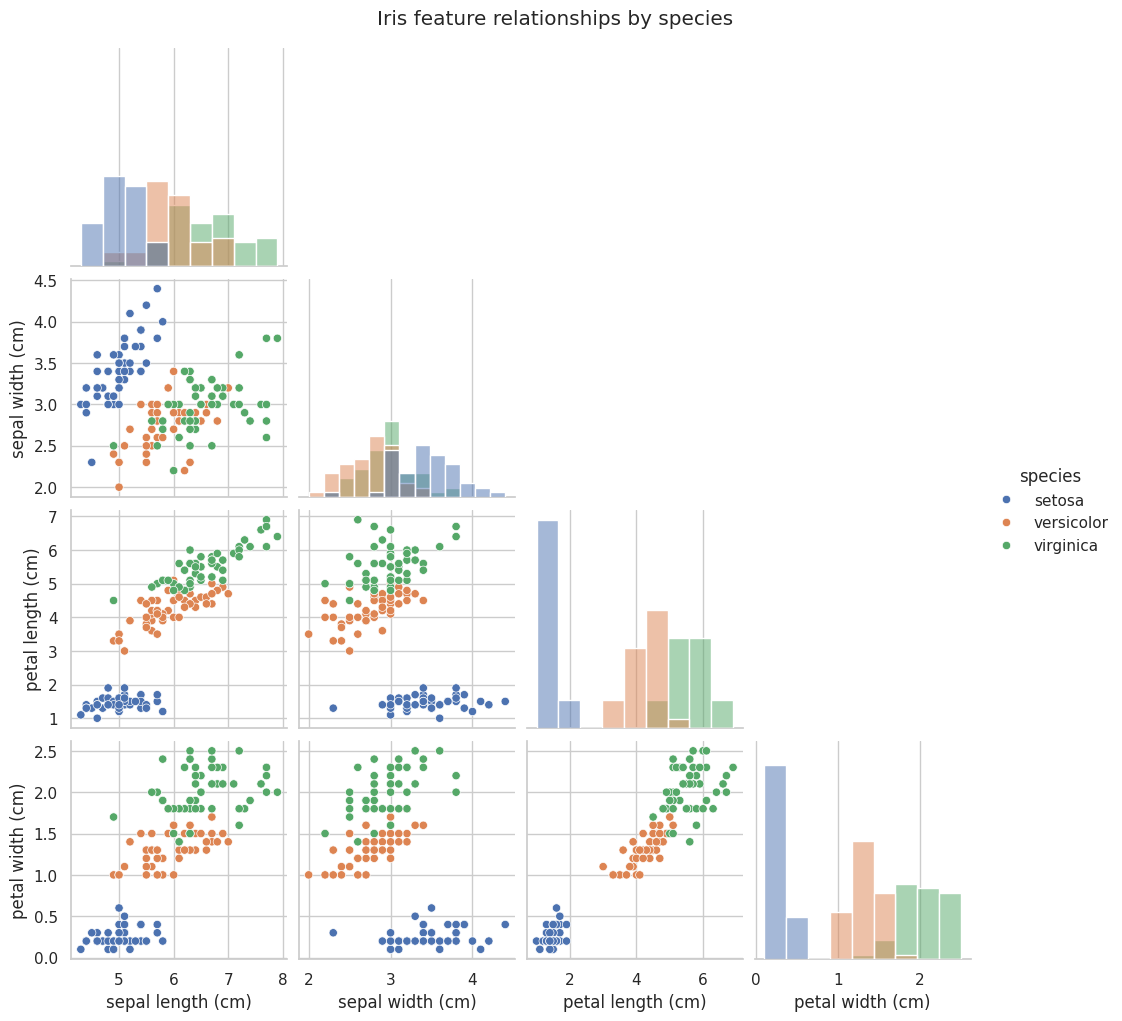

In [13]:
print("Missing values per column:")
display(df.isna().sum().to_frame("missing_values"))

print("Summary statistics:")
display(df.drop(columns=["target_id"]).describe().T)

sns.pairplot(
    df,
    vars=iris.feature_names,
    hue="species",
    diag_kind="hist",
    corner=True
)
plt.suptitle("Iris feature relationships by species", y=1.02)
plt.show()

## 3. Split features and target

We split before scaling. The scaler will be fitted only on the training data through each model pipeline, which prevents information from the test set leaking into training.

In [14]:
X = df[iris.feature_names]
y = df["target_id"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training samples: {len(X_train)} ({len(X_train)/len(X):.0%})")
print(f"Testing samples:  {len(X_test)} ({len(X_test)/len(X):.0%})")
print("\\nTraining class counts:")
display(y_train.map(dict(enumerate(iris.target_names))).value_counts().to_frame("count"))

Training samples: 120 (80%)
Testing samples:  30 (20%)
\nTraining class counts:


,count
target_id,
setosa,40
virginica,40
versicolor,40


## 4. Build and train the models

In [15]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    # Scaling is not required for decision trees, but including it keeps the workflow
    # consistent; it does not usually change tree splits.
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: training complete")

Logistic Regression: training complete
Decision Tree: training complete


## 5. Evaluate and compare

In [16]:
results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
    })

    print(f"\\n{name} — Classification Report")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=iris.target_names,
        zero_division=0
    ))

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))

\nLogistic Regression — Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

\nDecision Tree — Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.933,0.933,0.933,0.933


## 6. Confusion matrix heatmaps

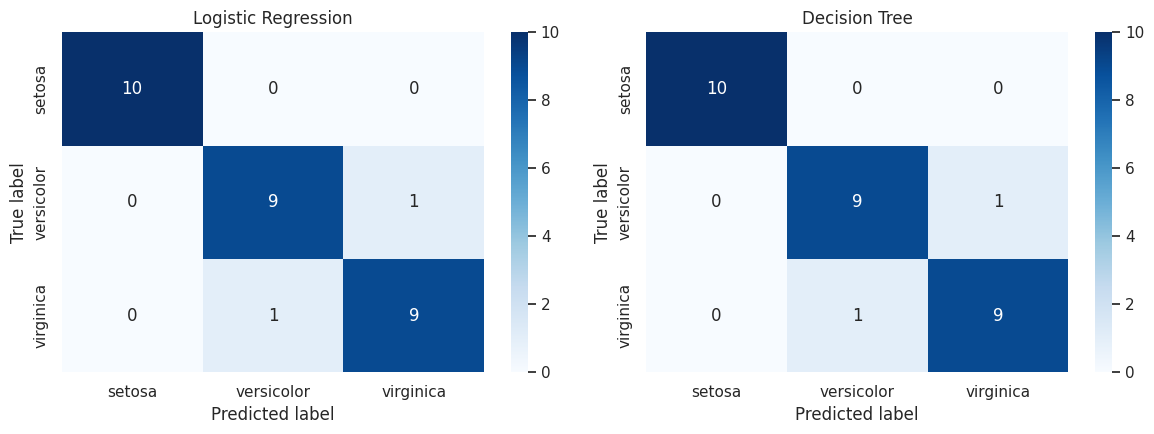

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

plt.tight_layout()
plt.show()

## 7. Decision-boundary visualization (two features)

This plot is a 2D illustration using only sepal length and sepal width. It is **not** the same as the final four-feature model evaluation above; it helps visualize how each classifier divides a simplified feature space.

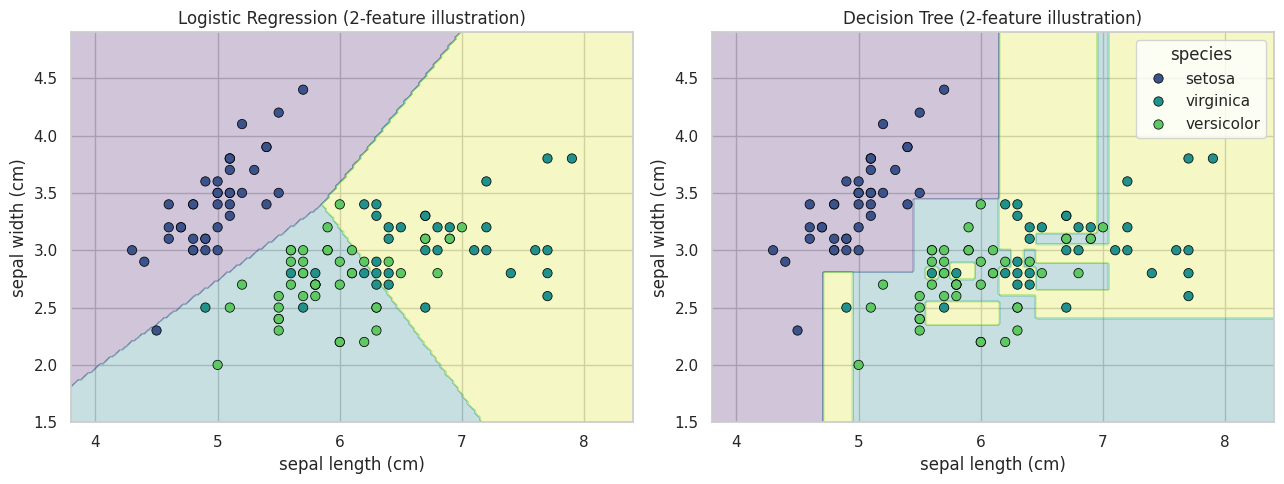

In [18]:
feature_pair = ["sepal length (cm)", "sepal width (cm)"]
X_train_2d = X_train[feature_pair]
y_train_2d = y_train

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x_min, x_max = X[feature_pair[0]].min() - 0.5, X[feature_pair[0]].max() + 0.5
y_min, y_max = X[feature_pair[1]].min() - 0.5, X[feature_pair[1]].max() + 0.5
xx, yy = __import__("numpy").meshgrid(
    __import__("numpy").arange(x_min, x_max, 0.02),
    __import__("numpy").arange(y_min, y_max, 0.02)
)
grid = pd.DataFrame({
    feature_pair[0]: xx.ravel(),
    feature_pair[1]: yy.ravel()
})

for ax, (name, classifier) in zip(axes, models.items()):
    # Train a separate illustrative 2-feature model for the decision-boundary plot.
    from sklearn.base import clone
    model_2d = clone(classifier)
    model_2d.fit(X_train_2d, y_train_2d)
    Z = model_2d.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")
    sns.scatterplot(
        data=pd.DataFrame({
            feature_pair[0]: X_train_2d[feature_pair[0]].values,
            feature_pair[1]: X_train_2d[feature_pair[1]].values,
            "species": y_train_2d.map(dict(enumerate(iris.target_names))).values
        }),
        x=feature_pair[0],
        y=feature_pair[1],
        hue="species",
        palette="viridis",
        edgecolor="black",
        s=45,
        ax=ax,
        legend=(ax is axes[1])
    )
    ax.set_title(f"{name} (2-feature illustration)")
    ax.set_xlabel(feature_pair[0])
    ax.set_ylabel(feature_pair[1])

plt.tight_layout()
plt.show()

## 8. Final conclusion

After running the notebook, use the metric table and confusion matrices to compare the models. Do not assume one model is better before inspecting the actual results.

**Suggested conclusion template (fill in after running):**

- The model with the higher test accuracy was **[model name]**.
- Its macro precision was **[value]**, macro recall was **[value]**, and macro F1-score was **[value]**.
- The confusion matrix shows which Iris classes were predicted correctly and which were confused.
- This experiment uses a fixed random seed and stratified split for reproducibility. Results describe this split; performance can vary with other splits or datasets.

## What each metric means
- **Accuracy:** fraction of all test predictions that are correct.
- **Precision (macro):** average class-level precision, giving each class equal weight.
- **Recall (macro):** average class-level recall, giving each class equal weight.
- **F1-score (macro):** average class-level harmonic mean of precision and recall.

## Submission checklist
- [ ] Run all cells from top to bottom.
- [ ] Confirm there are no errors and that tables/plots appear.
- [ ] Replace the conclusion placeholders with your observed results.
- [ ] Save this notebook as `Task1_Iris_Classification_Pipeline.ipynb`.
- [ ] Submit the `.ipynb` file as requested by the internship portal.